# Basics of spin dynamics

In [ ]:
#use packages and files

using Random
using LinearAlgebra
using SparseArrays

import Pkg; 
Pkg.add("HDF5")
Pkg.add("LaTeXStrings")
Pkg.add("CairoMakie")

using HDF5
using LaTeXStrings
using CairoMakie
CairoMakie.activate!((type = "svg"))

#using KrylovKit
#using Colors, ColorSchemes
#using GLM
#using FFTW
#using Interpolations
#using JLD2
#using Optim

In [6]:
include("../src/SpinLibrary.jl")
println("Download compete!")

Download compete!


# Example of spin dynamics

Our goal is to study the observables $\hat{J}^x$ and $\mathrm{Var}(\hat{J}^x)$ under the dynamics

$$ 
|\psi (t)\rangle = e^{-i\hat H t} |\mathrm{CSS}_X>
$$ 

with Hamiltonian $\hat H = (\hat{J}^z)^2 $ with qudit dimension $S$.

In [15]:
#single spin

#initial state

S = 10

init = init_cssX(S)

21-element Vector{Float64}:
 0.0009765625
 0.004367320268554275
 0.013460985109463102
 0.03297254495338695
 0.06797464279412048
 0.12159673762713571
 0.1922613234738235
 0.27189857117648186
 0.3466040300367195
 0.40022386008781824
 ⋮
 0.3466040300367195
 0.27189857117648186
 0.1922613234738235
 0.12159673762713571
 0.06797464279412048
 0.03297254495338695
 0.013460985109463102
 0.004367320268554275
 0.0009765625

In [16]:
#building Hamiltonian

Jz = Sz(S)
Ham = Jz*Jz #OAT Hamiltonian

21×21 Matrix{Float64}:
 100.0   0.0   0.0   0.0   0.0   0.0  …   0.0   0.0   0.0   0.0   0.0    0.0
   0.0  81.0   0.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0  64.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0  49.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0  36.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0   0.0  25.0  …   0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   ⋮                             ⋮    ⋱   ⋮                              ⋮
   0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0   0.0   0.0   0.0    0.0
   0.0   0.0   0.0   0.0   0.0   0.0      0.0   0.0   0

In [18]:
#time evolution

tlen = 201
tmax = 2*pi
les_t = range(0, tmax, tlen)

vp, P, Pm = diagonalisation(Ham)

#observable : mean and variance of Jx
Jx = Sx(S)
Jx2 = Jx*Jx

MeanX = zeros(Float64, tlen)
VarX = zeros(Float64, tlen)
for kt in 1:tlen
    t = les_t[kt]
    psi_t = evolution(vp, P, Pm, init, t)
    mx = real(psi_t'*Jx*psi_t)
    MeanX[kt] = mx
    VarX[kt] = real(psi_t'*Jx2*psi_t) - mx*mx
end

#for saving the data, then use load_object to reopen them
# path = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# save_object("$path/test_evolution_Jx_S$(S).jld2", MeanX)
# save_object("$path/test_evolution_time_S$(S).jld2", les_t)
# save_object("$path/test_evolution_VarX_S$(S).jld2", VarX)

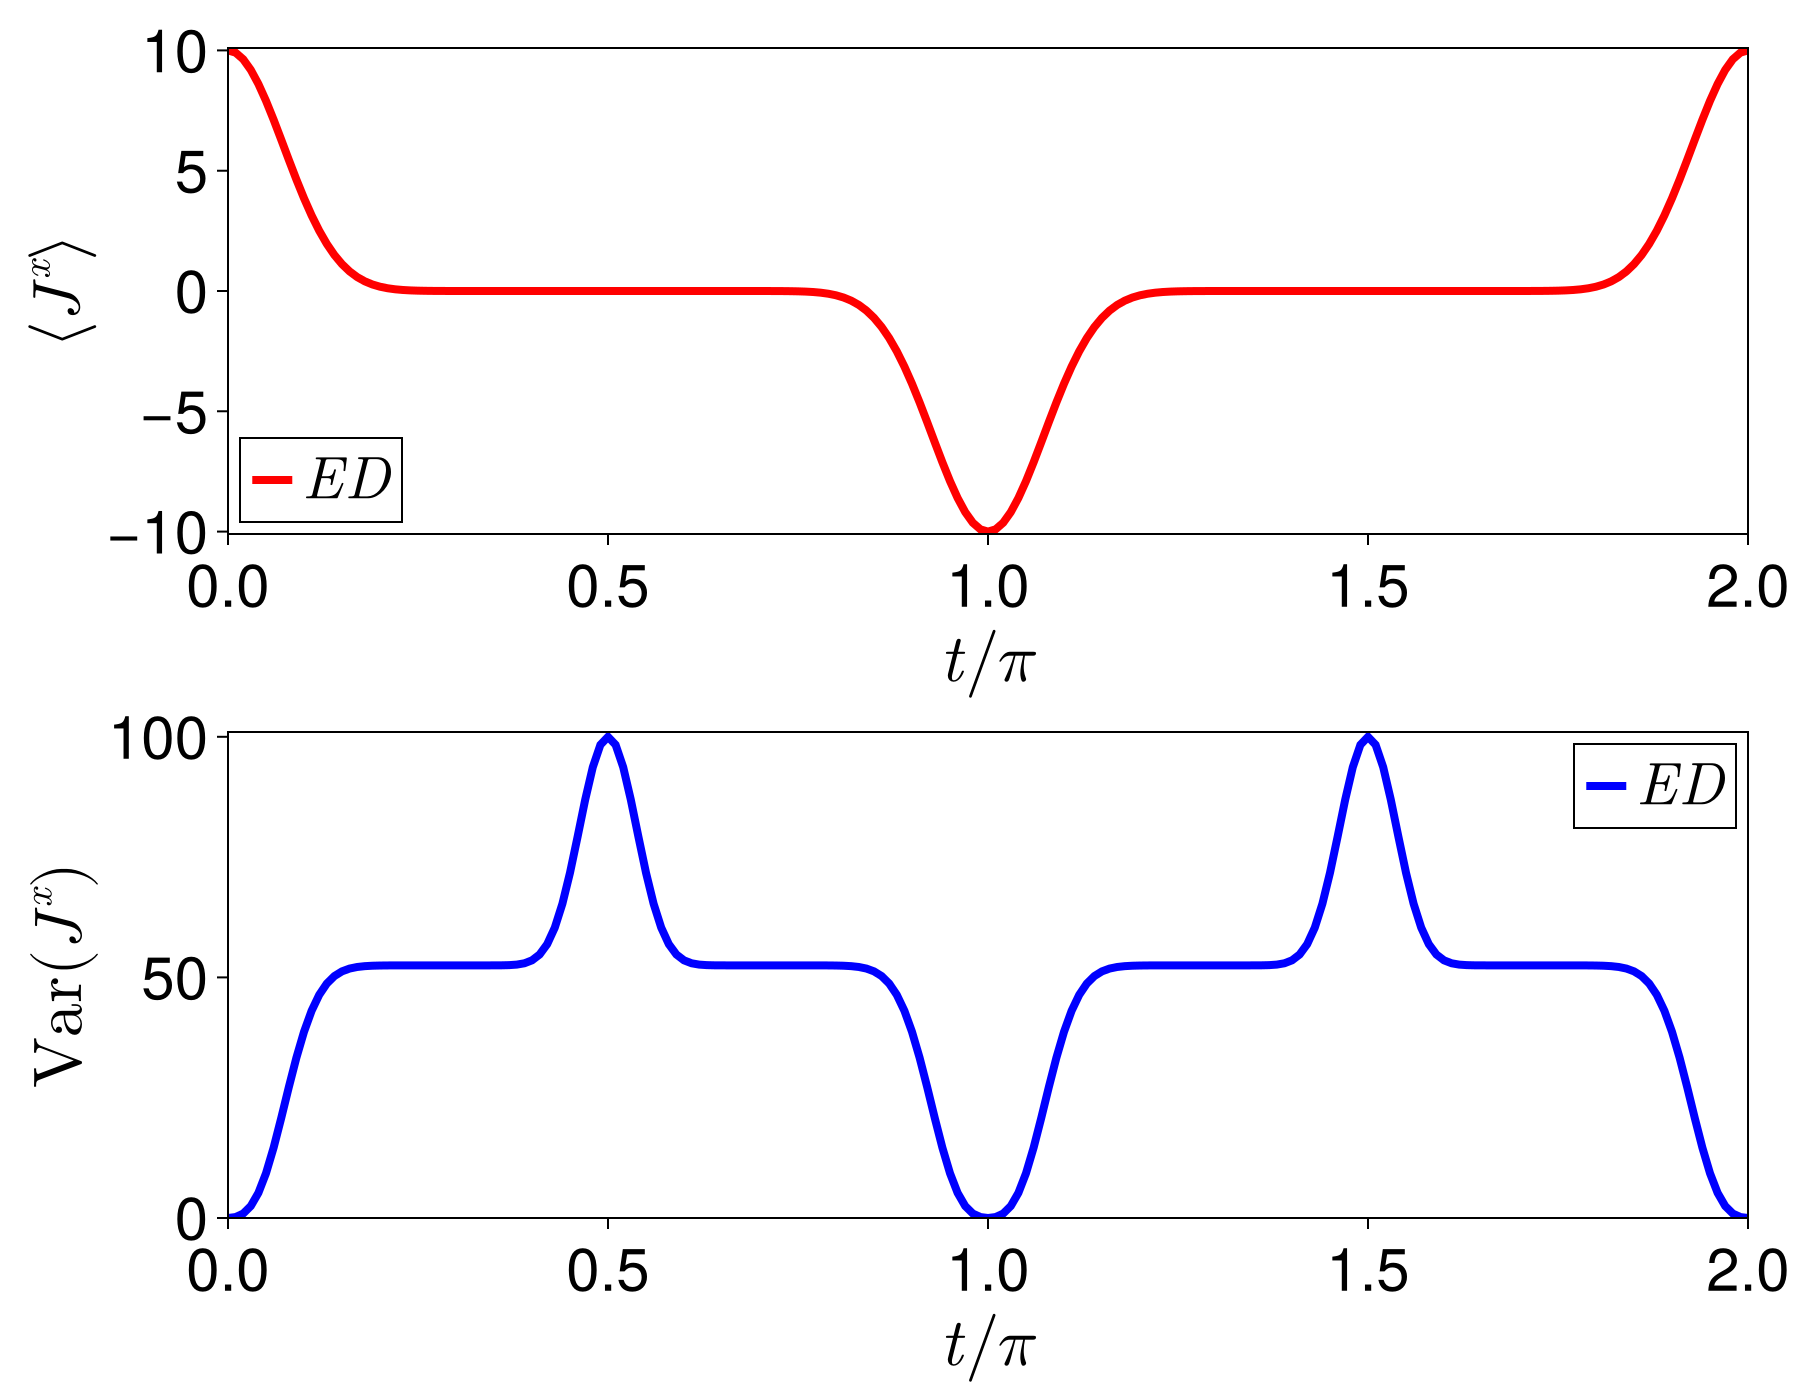

In [19]:
#plotting

f = Figure(font="Helvetica", figure_padding=(10, 26, 10, 24), size=(900, 700), backgroundcolor=:white, fontsize=30, tickfontsize=30)
ax1 = Axis(f[1, 1], xlabel= L"t/\pi", ylabel=L"\langle J^{x} \rangle", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)
ax2 = Axis(f[2, 1], xlabel= L"t/\pi", ylabel=L"\mathrm{Var} ( J^{x} )", xlabelsize=34, ylabelsize=34, xgridvisible = false, ygridvisible = false)


lines!(ax1, les_t/pi, MeanX; linewidth=4, label=L"ED", color = :red)
lines!(ax2, les_t/pi, VarX; linewidth=4, label=L"ED", color = :blue)

axislegend(ax1, position = :lb)
axislegend(ax2, position = :rt)

limits!(ax1, 0, tmax/pi, -S*1.01, S*1.01)
limits!(ax2, 0, tmax/pi, 0, S*S*1.01)

f1 = current_figure()
#for saving the figure, change path and name
# pathF = "C:/Users/trifa/OneDrive/Documents/papers/Little_cats/Figures"
# name = "C_vs_t_EDvL_unif2D_N$(N)_S$(S)"
# save("$pathF/$name.png", f1)
f1